Import necessery libraries

In [67]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from pandas.api.types import is_numeric_dtype

Load dataset

In [41]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [42]:
df = sns.load_dataset('car_crashes')

In [43]:
df.shape

(51, 8)

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.isna().sum()

total             0
speeding          0
alcohol           0
not_distracted    0
no_previous       0
ins_premium       0
ins_losses        0
abbrev            0
dtype: int64

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   total           51 non-null     float64
 1   speeding        51 non-null     float64
 2   alcohol         51 non-null     float64
 3   not_distracted  51 non-null     float64
 4   no_previous     51 non-null     float64
 5   ins_premium     51 non-null     float64
 6   ins_losses      51 non-null     float64
 7   abbrev          51 non-null     str    
dtypes: float64(7), str(1)
memory usage: 3.3 KB


In [6]:
df['abbrev'].value_counts()

abbrev
AL    1
AK    1
AZ    1
AR    1
CA    1
CO    1
CT    1
DE    1
DC    1
FL    1
GA    1
HI    1
ID    1
IL    1
IN    1
IA    1
KS    1
KY    1
LA    1
ME    1
MD    1
MA    1
MI    1
MN    1
MS    1
MO    1
MT    1
NE    1
NV    1
NH    1
NJ    1
NM    1
NY    1
NC    1
ND    1
OH    1
OK    1
OR    1
PA    1
RI    1
SC    1
SD    1
TN    1
TX    1
UT    1
VT    1
VA    1
WA    1
WV    1
WI    1
WY    1
Name: count, dtype: int64

In [47]:
df.describe()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,15.790196,4.998196,4.886784,13.573176,14.004882,886.957647,134.493137
std,4.122002,2.017747,1.729133,4.508977,3.764672,178.296285,24.835922
min,5.900000,1.792000,1.593000,1.760000,5.900000,641.960000,82.750000
25%,12.750000,3.766500,3.894000,10.478000,11.348000,768.430000,114.645000
50%,15.600000,4.608000,4.554000,13.857000,13.775000,858.970000,136.050000
75%,18.500000,6.439000,5.604000,16.140000,16.755000,1007.945000,151.870000
max,23.900000,9.450000,10.038000,23.661000,21.280000,1301.520000,194.780000


## Data preprocessing

Apply lebel encoding in abbrev

In [48]:
le = LabelEncoder()
df['abbrev'] = le.fit_transform(df['abbrev'])
df.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,1
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,0
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,3
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,2
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,4


In [49]:
df.columns

Index(['total', 'speeding', 'alcohol', 'not_distracted', 'no_previous',
       'ins_premium', 'ins_losses', 'abbrev'],
      dtype='str')

In [50]:
df.corr()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
total,1.000000,0.611548,0.852613,0.827560,0.956179,-0.199702,-0.036011,0.043213
speeding,0.611548,1.000000,0.669719,0.588010,0.571976,-0.077675,-0.065928,0.079701
alcohol,0.852613,0.669719,1.000000,0.732816,0.783520,-0.170612,-0.112547,0.135754
not_distracted,0.827560,0.588010,0.732816,1.000000,0.747307,-0.174856,-0.075970,0.004800
no_previous,0.956179,0.571976,0.783520,0.747307,1.000000,-0.156895,-0.006359,-0.029075
ins_premium,-0.199702,-0.077675,-0.170612,-0.174856,-0.156895,1.000000,0.623116,-0.175018
ins_losses,-0.036011,-0.065928,-0.112547,-0.075970,-0.006359,0.623116,1.000000,-0.134035
abbrev,0.043213,0.079701,0.135754,0.004800,-0.029075,-0.175018,-0.134035,1.000000


<Axes: >

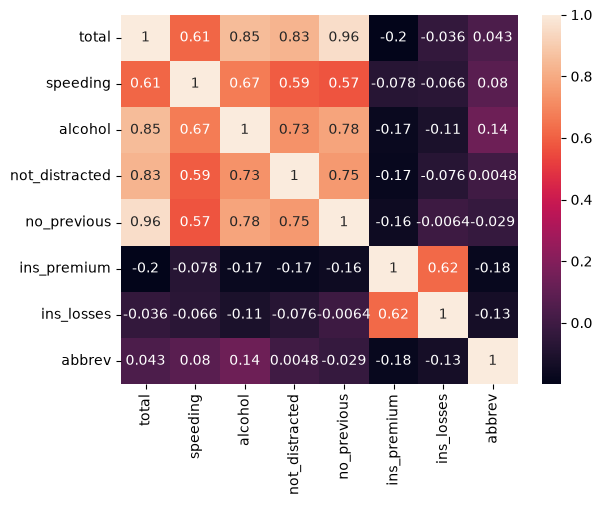

In [51]:
sns.heatmap(df.corr(), annot=True)

## Apply MinMax scaler

In [53]:
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,1
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,0


In [56]:
min_max = MinMaxScaler()

df['speeding'] = min_max.fit_transform(df[['speeding']])

In [57]:
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,0.723426,5.640,18.048,15.040,784.55,145.08,1
1,18.1,0.735048,4.525,16.290,17.014,1053.48,133.93,0


change MinMax scaler's parameters

In [60]:
min_max_up = MinMaxScaler(feature_range=(1,5))

df['speeding'] = min_max_up.fit_transform(df[['speeding']])

df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,5.640,18.048,15.040,784.55,145.08,1
1,18.1,3.940193,4.525,16.290,17.014,1053.48,133.93,0


In [63]:
x = df.drop(['total'], axis=1)
x.head(2)

,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,3.893706,5.640,18.048,15.040,784.55,145.08,1
1,3.940193,4.525,16.290,17.014,1053.48,133.93,0


In [66]:
y = df[['total']]
y.head()

,total
0,18.8
1,18.1
2,18.6
3,22.4
4,12.0
